In [17]:
import pandas as pd
import joblib
import sys

In [18]:
# Point to src folder
sys.path.append('../src') 
from models import get_tree_models, train_model
from evaluation import evaluate_classification, plot_confusion_matrix

In [19]:
# Load Data
X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()


In [20]:
# Load Preprocessor & Transform Data

preprocessor = joblib.load('../models/preprocessor.pkl')

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Load uninitialized models
models = get_tree_models()

# Random Forest Classifier

Training Random Forest...

--- Random Forest Performance ---
Accuracy: 0.8171
Precision: 0.6673
Recall: 0.3443
F1-Score: 0.4543
ROC-AUC: 0.7707


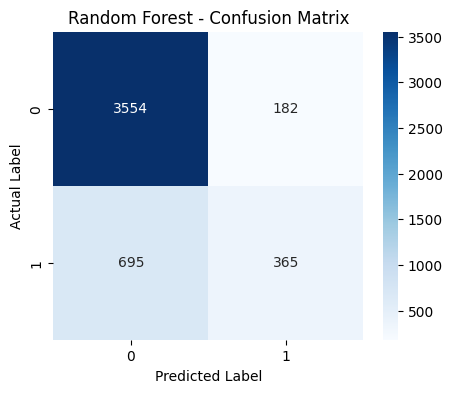

In [22]:
print("Training Random Forest...")
rf_model = models['Random Forest']

# Train and save
rf_fitted = train_model(rf_model, X_train_processed, y_train)
joblib.dump(rf_fitted, '../models/random_forest_model.pkl')

# Predict
rf_pred = rf_fitted.predict(X_test_processed)
rf_pred_proba = rf_fitted.predict_proba(X_test_processed)[:, 1]

# Evaluate
evaluate_classification(y_test, rf_pred, rf_pred_proba, model_name="Random Forest")
plot_confusion_matrix(y_test, rf_pred, model_name="Random Forest")

# XGBoost

Training XGBoost...

--- XGBoost Performance ---
Accuracy: 0.7784
Precision: 0.4987
Recall: 0.5557
F1-Score: 0.5257
ROC-AUC: 0.7593


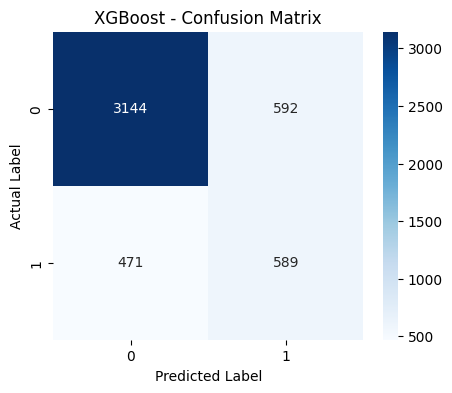

In [21]:
print("Training XGBoost...")
xgb_model = models['XGBoost']

# Train and save
xgb_fitted = train_model(xgb_model, X_train_processed, y_train)
joblib.dump(xgb_fitted, '../models/xgboost_model.pkl')

# Predict
xgb_pred = xgb_fitted.predict(X_test_processed)
xgb_pred_proba = xgb_fitted.predict_proba(X_test_processed)[:, 1]

# Evaluate
evaluate_classification(y_test, xgb_pred, xgb_pred_proba, model_name="XGBoost")
plot_confusion_matrix(y_test, xgb_pred, model_name="XGBoost")

# LightGBM

Training LightGBM...
[LightGBM] [Info] Number of positive: 4241, number of negative: 14939
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001232 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3350
[LightGBM] [Info] Number of data points in the train set: 19180, number of used features: 36
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


c:\Users\Anmoy\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Anmoy\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Anmoy\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Anmoy\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038


--- LightGBM Performance ---
Accuracy: 0.7675
Precision: 0.4798
Recall: 0.6151
F1-Score: 0.5391
ROC-AUC: 0.7835


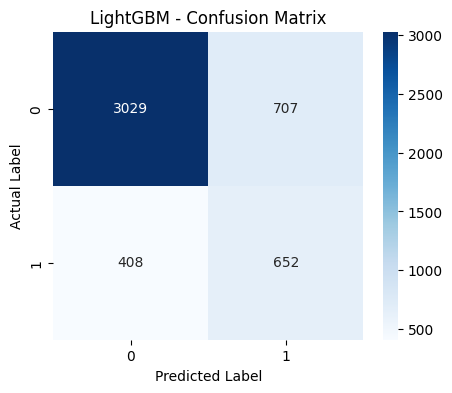

In [23]:
print("Training LightGBM...")
lgbm_model = models['LightGBM']

# Train and save
lgbm_fitted = train_model(lgbm_model, X_train_processed, y_train)
joblib.dump(lgbm_fitted, '../models/lightgbm_model.pkl')

# Predict
lgbm_pred = lgbm_fitted.predict(X_test_processed)
lgbm_pred_proba = lgbm_fitted.predict_proba(X_test_processed)[:, 1]

# Evaluate
evaluate_classification(y_test, lgbm_pred, lgbm_pred_proba, model_name="LightGBM")
plot_confusion_matrix(y_test, lgbm_pred, model_name="LightGBM")